# 01 — EDA: Wongnai Reviews + Wisesight Sentiment

**เป้าหมายของ notebook นี้:** ทำความรู้จักข้อมูลก่อนเทรนโมเดล ไม่ได้ทำ EDA เพื่อให้มีกราฟสวยๆ
แต่เพื่อ **ตอบคำถามที่มีผลต่อการตัดสินใจ** ในขั้นต่อไป ทุก section จะจบด้วย "→ การตัดสินใจ"

| # | คำถาม | กระทบอะไร |
|---|---|---|
| Q1 | ข้อมูลสะอาดไหม (ซ้ำ, ว่าง, train/test รั่วถึงกัน) | ความน่าเชื่อถือของตัวเลข evaluation |
| Q2 | class สมดุลไหม | ใช้ metric ตัวไหน, split แบบไหน |
| Q3 | รีวิว 3 ดาวควรทำอย่างไร | นิยาม label |
| Q4 | รีวิวยาวแค่ไหน | `max_length` ของ WangchanBERTa (Phase 2) |
| Q5 | คำไหนแยกบวก/ลบได้ดี | ความเข้าใจโมเดล + seed keyword ของ aspect (Phase 3) |
| Q6 | Wisesight ต่างจาก Wongnai อย่างไร | จะใช้ Wisesight ทำอะไร |

> รันบน Colab: `!git clone https://github.com/Riewta/mlproj && %cd mlproj && !pip install -q -r requirements-notebooks.txt && !apt-get -qq install fonts-thai-tlwg`
> แล้ว restart runtime หนึ่งครั้ง (เพื่อให้ matplotlib เห็นฟอนต์ไทย)

In [1]:
import sys
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))  # so we can import src.*

from src.data.load import load_wongnai, load_wisesight, stars_to_binary, wisesight_to_binary
from src.viz import use_thai_font

FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
use_thai_font()

'Thonburi'

## 1. โหลดข้อมูล

ใช้ไฟล์ Parquet ที่ Hugging Face host ไว้ผ่าน `huggingface_hub` แทน `datasets.load_dataset`
เพราะเบากว่าและไม่ต้องพึ่ง loading script (Wongnai เวอร์ชันเก่าใช้ script ซึ่ง `datasets` รุ่นใหม่เลิกรองรับแล้ว)

loader ใน `src/data/load.py` แปลงทั้งสอง dataset ให้มีคอลัมน์เหมือนกัน: `text, label_raw, split, source`
ทำให้โค้ดส่วนถัดไปไม่ต้องรู้ว่าข้อมูลมาจากไหน

ข้อสังเกต: HF เก็บ `star_rating` เป็น 0–4 (index ของ ClassLabel) loader บวก 1 ให้เป็น 1–5 ดาวแล้ว
ถ้าลืมจุดนี้ นิยาม "≥4 = บวก" จะเลื่อนไปหนึ่งดาวทั้งชุดโดยไม่มี error เตือนเลย

In [2]:
wn = load_wongnai()
ws = load_wisesight()
print(wn.groupby("split").size().to_dict(), ws.groupby("split").size().to_dict())
wn.head(3)

/Users/riewta/Downloads/mlproj/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'test': 6203, 'train': 40000} {'test': 2671, 'train': 21628, 'validation': 2404}


,text,label_raw,split,source
0,ร้านอาหารใหญ่มากกกกกกก \nเลี้ยวเข้ามาเจอห้องน้...,3,train,wongnai
1,อาหารที่นี่เป็นอาหารจีนแคะที่หากินยากในบ้านเรา...,4,train,wongnai
2,ปอเปี๊ยะสด ทุกวันนี้รู้สึกว่าหากินยาก (ร้านที่...,3,train,wongnai


## 2. Q1 — คุณภาพข้อมูล

เช็กสามอย่างที่ทำให้ตัวเลข evaluation โกหกเราได้:
1. **ค่าว่าง / ข้อความสั้นผิดปกติ**
2. **ข้อความซ้ำใน train**: ทำให้โมเดลจำแทนที่จะเรียนรู้
3. **ข้อความที่อยู่ทั้งใน train และ test (leakage)**: test จะง่ายกว่าความจริง

In [3]:
def quality(df):
    return df.groupby("split").text.agg(
        rows="size",
        duplicates=lambda s: s.duplicated().sum(),
        min_chars=lambda s: s.str.len().min(),
    )

def overlap(df, a, b):
    return len(set(df.text[df.split == a]) & set(df.text[df.split == b]))

display(quality(wn), quality(ws))
print("Wongnai train∩test:", overlap(wn, "train", "test"))
print("Wisesight train∩test:", overlap(ws, "train", "test"), "train∩val:", overlap(ws, "train", "validation"))

,rows,duplicates,min_chars
split,,,
test,6203,1,200
train,40000,7,200


,rows,duplicates,min_chars
split,,,
test,2671,0,1
train,21628,16,1
validation,2404,1,1


Wongnai train∩test: 2


Wisesight train∩test: 5 train∩val: 2


In [4]:
dups = ws.text[ws.split == "train"].value_counts()
dups[dups > 1].head(10)

text
พรบ.คู่ชีวิตไทยนี่ถึงไหนแล้วคะ ไต้หวันไปไกลแล้วนะ............ 🤔                               2
เท่าไหร่                                                                                      2
เซนทรัลราม2มีมั้ยค่ะ                                                                          2
อุดรมีไหมค่ะ                                                                                  2
วันนี้มีของรึยัง                                                                              2
โตโยต้า วิส เท่าไรคับ                                                                         2
toyota ผมแนะนำถ้าใครซื้ออย่าเอารถค้างสต็อคตามปากคนขาย viosผมเจอปัญหาแล้วแต่ camryยังสบายดี    2
ชุมพรมั้ยอ้ะ?!😂                                                                               2
รสชาติเปนยังไงคะ                                                                              2
แท็กซี่หรือไม่แท็กซี่                                                                         2
Name: count, dtype: int64

**สิ่งที่เจอ**
- Wongnai สะอาดมาก ซ้ำแค่หลักหน่วย และ **ทุกรีวิวยาว ≥ 200 ตัวอักษร** แปลว่าคนทำ dataset กรองรีวิวสั้นทิ้งไปแล้ว
  ผลที่ตามมาสำคัญมาก: โมเดลที่เทรนจาก Wongnai **ไม่เคยเห็นข้อความสั้นแบบที่คนพิมพ์ใน LINE** ("อร่อยมาก", "แพงไป")
  ตัวเลขบน test set ของ Wongnai จึงบอกไม่ได้ว่าโมเดลจะทำงานดีกับ LINE bot
- Wisesight มีข้อความซ้ำมากกว่า (ส่วนใหญ่เป็นคำถามสั้นๆ เช่น "เท่าไหร่", "อุดรมีไหมคะ") และมีข้อความรั่วข้าม train/test อยู่หลักหน่วย

**→ การตัดสินใจ**
- ลบข้อความซ้ำ **ก่อน** split และลบแถวใน train ที่ซ้ำกับ test/validation ทิ้ง (เก็บ test ไว้ตามที่ publish เพื่อเทียบกับงานอื่นได้)
- ต้องมี test set ข้อความสั้นแยกต่างหาก (Wisesight ช่วยตรงนี้ได้ ดู section 7)

## 3. Q2 + Q3 — การกระจายของ rating และนิยาม label

split,test,train
label_raw,,
1,0.008,0.010
2,0.033,0.046
3,0.307,0.304
4,0.480,0.469
5,0.172,0.170


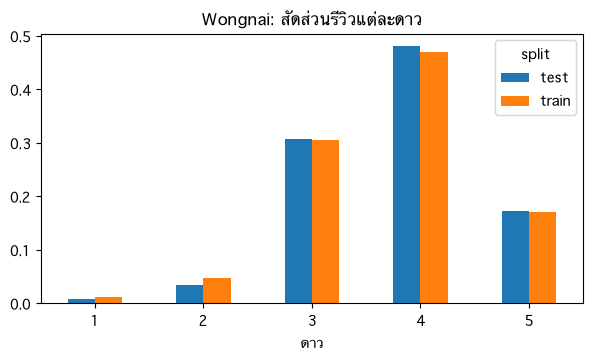

In [5]:
dist = wn.groupby("split").label_raw.value_counts(normalize=True).unstack(0)
dist.plot.bar(title="Wongnai: สัดส่วนรีวิวแต่ละดาว", xlabel="ดาว", rot=0, figsize=(7, 3.5))
plt.savefig(FIGS / "wongnai_rating_dist.png", dpi=120, bbox_inches="tight")
dist.round(3)

train กับ test มีสัดส่วนดาวเกือบเท่ากัน (ดี: test เป็นตัวแทนของ train)
แต่ข้อมูล **เบ้หนักไปทางบวก** และ 3 ดาวมีมากถึง ~30%

เทียบนิยาม label สองแบบ:
- **A:** ≥4 บวก, ≤2 ลบ, ตัด 3 ทิ้ง (แบบที่ baseline เดิมใช้)
- **B:** ≥4 บวก, ≤3 ลบ (เก็บทุกแถว)

In [6]:
tr = wn[wn.split == "train"].drop_duplicates("text")
y_a = stars_to_binary(tr.label_raw).dropna()  # A: drop 3 stars
y_b = (tr.label_raw >= 4).astype(int)         # B: 3 stars = negative

for name, y in [("A", y_a), ("B", y_b)]:
    print(f"{name}: rows={len(y):,}  negative={1 - y.mean():.1%}  always-positive accuracy={y.mean():.1%}")

A: rows=27,822  negative=8.1%  always-positive accuracy=91.9%
B: rows=39,993  negative=36.1%  always-positive accuracy=63.9%


**อ่านตัวเลขนี้ยังไง:** ภายใต้นิยาม A โมเดลโง่ๆ ที่ตอบ "บวก" ทุกครั้งได้ accuracy ~92% แล้ว
ดังนั้นถ้าเราเห็น accuracy 95% มันดีกว่าการเดาแค่ 3 จุด ซึ่งน้อยกว่าที่ตัวเลขดูเหมือน

ลองดูตัวอย่างรีวิว 3 ดาวก่อนตัดสินใจว่าจะทำอะไรกับมัน:

In [7]:
for t in tr.text[tr.label_raw == 3].sample(4, random_state=7):
    print("•", t[:260].replace("\n", " "), "…\n")

• ทางกลับกทม เห็นร้านน่าถ่ายรูปเลยแวะเช็คอิน ประทับไจมากก มีมุมถ่ายรูปสวยๆ กาแฟรสชาตใช้ได้ ภายในร้านตกแต่งสวยเว่อ หรูหรา คลาสสิค โซฟาสวยงามน่านั่ง เสริฟกาแฟเป่นเซ็ทคือน่ารัก ได้รูปกลับไปประมาน50รูปเหมาะสำหร่าคนชอบร้านสวยๆเก๋ๆถ่ายรูปอัพรูปเช็คอิน …

• จากที่ไปนั่งฟังเพลง ทานข้าว หลายๆ ครั้ง สังเกตตัวเองว่า มากี่ครั้งก็สั่งอยู่ 3 เมนูนี้ แล้วลากยาว ฮ่าๆ  ร้านนี้ ดนตรีจะออกแนวชิวๆ บรรยากาศนี้ ถ้าไม่ได้ไปหน้าฝน ส่วนรสชาติอาหารพอใช้ได้ค่ะ  ร้านนี้อยู่ ถ.ศรีนครินทร์ ตรงข้าม ซีคอนฯ ซ.อะไร จำไม่ได้ แหะๆ …

• อาหารให้ 2.5-2.9จาก5 คืออาหารพอใช้ได้ แบบทานได้ไม่ถึงกับวางมีดส้อมและผลักออก บรรยากาศ 2.5จาก5 มันทึมๆชวน depress งัยไม่รู้ Traditional Escargots de Bourgognein Butter, Parsley & Garlic เค็มไปหน่อย Dessert ไม่ชอบเลยสักจาน  โดยรวมให้ 2.85 Filet Mignon,Pommes de  …

• เอาจริง ร้านนี้ ข้าวมันไก่อร่อยพอทานได้ ไม่ว่าจะตัวข้าว ไก่และน้ำจิ้ม รสชาติกลางๆ แต่ที่ทำให้นึกถึงแล้วกลับมาทานนานๆที ก้อเพราะติดใจน้ำซุปต้มยำ (20 บาท) ที่ทางร้านเอาซี่โครงและตีนขาไก่ มาทำต้มยำน้ำใส ใช้พริกสด อร่อยแซ่บ ทานกับข้

รีวิว 3 ดาวส่วนใหญ่ **ทั้งชมและติในรีวิวเดียว** ("อาหารอร่อย แต่แพง/รอนาน") ไม่ใช่ "ลบ" จริงๆ
ถ้าบังคับให้เป็นลบ (นิยาม B) เราสอนโมเดลด้วย label ที่มี noise เยอะ

**→ การตัดสินใจ**
- ใช้ **นิยาม A** (ตัด 3 ดาว) เป็นงาน sentiment หลัก เพื่อให้เทียบกับ baseline เดิมได้ตรงๆ
- metric หลักคือ **macro-F1 และ F1 ของ class ลบ**, ไม่ใช้ accuracy, และรายงาน confusion matrix ทุกครั้ง
- ใช้ **stratified split** เสมอ เพื่อให้ทุก split มี class ลบ ~8% เท่ากัน (ไม่งั้น validation อาจมี class ลบน้อยจนตัวเลขแกว่ง)
- รีวิว 3 ดาว **ไม่ทิ้ง** แต่เก็บไว้ใช้สองที่: (1) error analysis เรื่องรีวิวผสม (Phase 2) (2) เป็นแหล่งข้อมูลชั้นดีของ aspect (Phase 3) เพราะชมเรื่องหนึ่ง ติอีกเรื่อง

## 4. Q4 — ความยาวรีวิว

นับจำนวนคำหลังตัดคำด้วย PyThaiNLP (`newmm` ค่า default)
ภาษาไทยไม่มีเว้นวรรคระหว่างคำ **การนับคำจึงขึ้นกับตัวตัดคำ** ตัวเลขนี้เป็นค่าประมาณ ไม่ใช่ความจริงแท้

In [8]:
from pythainlp.tokenize import word_tokenize

def tokenize(text):
    return [w for w in word_tokenize(text) if not w.isspace()]

wn["tokens"] = wn.text.map(tokenize)  # ~20 s
wn["n_words"] = wn.tokens.map(len)
wn.groupby("label_raw").n_words.median()

label_raw
1    102.0
2    111.0
3     92.0
4     89.0
5     85.0
Name: n_words, dtype: float64

0.50     90.0
0.90    249.0
0.95    347.0
Name: n_words, dtype: float64

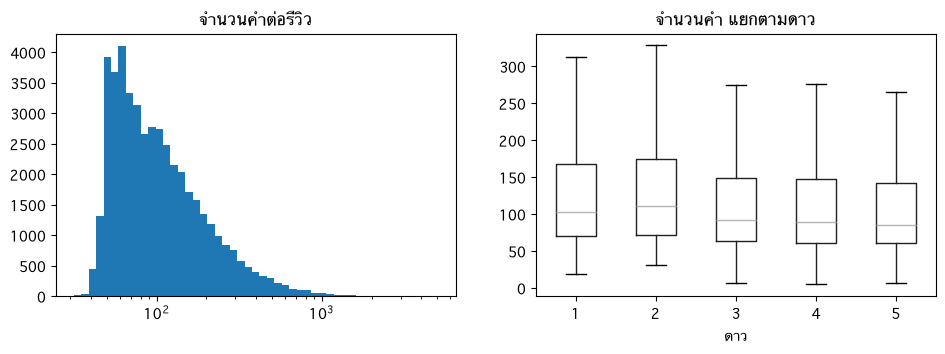

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(wn.n_words, bins=np.logspace(1.5, 3.7, 50))
ax[0].set_xscale("log")
ax[0].set_title("จำนวนคำต่อรีวิว")
wn.boxplot(column="n_words", by="label_raw", showfliers=False, grid=False, ax=ax[1])
ax[1].set_title("จำนวนคำ แยกตามดาว"); ax[1].set_xlabel("ดาว")
fig.suptitle("")
plt.savefig(FIGS / "wongnai_length.png", dpi=120, bbox_inches="tight")

wn.n_words.quantile([0.5, 0.9, 0.95]).round()

In [10]:
# WangchanBERTa takes up to 416 subword tokens; one newmm word ≈ 1–1.5 subwords
for limit in [128, 256, 416]:
    print(f"longer than {limit} words: {(wn.n_words > limit).mean():.1%}")

longer than 128 words: 31.0%
longer than 256 words: 9.5%
longer than 416 words: 3.4%


**สิ่งที่เจอ**
- ความยาวกระจายแบบ long tail: ส่วนใหญ่ร้อยกว่าคำ แต่มีบางรีวิวยาวหลายพันคำ
- **รีวิวดาวน้อยยาวกว่า** รีวิวดาวมาก (คนที่ไม่พอใจมักเล่าละเอียด) แปลว่าความยาวเองก็เป็น signal อ่อนๆ
  แต่เป็น signal ที่ **ไม่ควร** ให้โมเดลพึ่ง เพราะใน LINE ข้อความลบอาจสั้นมาก ("ห่วย")

**→ การตัดสินใจ (Phase 2)**
- ตั้ง `max_length=416` (เพดานของโมเดล) ถ้า 1 คำ ≈ 1–1.5 subword รีวิวราว **3–10% จะยังถูกตัด** (ดูตัวเลข 256/416 คำข้างบน)
  ถ้าเครื่องไม่พอ 256 ก็ครอบคลุม ~70–90% แลกกับเทรนเร็วขึ้นมาก: เป็นอีกตัวแปรที่ควรทดลอง
- รีวิวลบมักสรุปความรู้สึกไว้ **ท้ายรีวิว** ("...คงไม่มาซ้ำ") จะลองตัดแบบ **head + tail** (เก็บต้นและท้าย ตัดตรงกลาง) เทียบกับตัดท้ายทิ้งปกติ
  นี่คือการทดลองที่ดีสำหรับ MLflow/W&B
- TF-IDF ไม่มีปัญหาเรื่องความยาว เป็นข้อได้เปรียบของ baseline ที่ควรเขียนไว้ในตารางเทียบ

## 5. Q5 — คำไหนแยกบวก/ลบได้ดี

**ลองแบบตรงไปตรงมาก่อน:** นับคำที่เจอบ่อยสุดในแต่ละ class

In [11]:
from pythainlp.corpus.common import thai_stopwords
from src.cleaner import KEEP_WORDS  # negation/intensifier words the baseline keeps

STOP = set(thai_stopwords()) - KEEP_WORDS

def content_words(tokens):
    return [w for w in tokens if w not in STOP and len(w) > 1 and any(c.isalpha() for c in w)]

lab = wn[wn.split == "train"].drop_duplicates("text").copy()
lab["y"] = stars_to_binary(lab.label_raw)
lab = lab.dropna(subset=["y"])

neg = Counter(w for toks in lab.tokens[lab.y == 0] for w in content_words(toks))
pos = Counter(w for toks in lab.tokens[lab.y == 1] for w in content_words(toks))
pd.DataFrame({"negative": [w for w, _ in neg.most_common(15)],
              "positive": [w for w, _ in pos.most_common(15)]})

,negative,positive
0,ไม่,ร้าน
1,ร้าน,ไม่
2,เลย,เลย
3,มาก,อร่อย
4,กิน,มาก
5,รสชาติ,ทาน
6,สั่ง,ดี
7,ทาน,เมนู
8,อร่อย,รสชาติ
9,อาหาร,อาหาร


สองคอลัมน์แทบเหมือนกัน ("ร้าน", "อาหาร", "อร่อย"...) เพราะความถี่ดิบบอกแค่ว่า **คำไหนพบบ่อยในรีวิวร้านอาหาร** ไม่ได้บอกว่าคำไหน **แยก** class
และ class บวกมีข้อมูลมากกว่า ~11 เท่า คำทั่วไปเลยชนะทุกอย่าง

**ใช้ log-odds ratio with informative Dirichlet prior** (Monroe, Colaresi & Quinn, 2008) แทน:
- เทียบ "อัตราการเจอคำนี้ในรีวิวลบ" กับ "ในรีวิวบวก" (log-odds) ทำให้ขนาด class ไม่มีผล
- บวก prior จากความถี่รวม ทำให้คำหายาก (เจอ 2 ครั้ง ทั้งคู่อยู่ใน class ลบ) ไม่พุ่งขึ้นอันดับหนึ่ง
- หารด้วย standard deviation ได้ z-score: ยิ่งห่างจาก 0 ยิ่งมั่นใจว่าคำนี้เอียงไปทาง class นั้นจริง

นี่คือวิธีเดียวกับที่ใช้ศึกษาว่านักการเมืองพรรคไหนใช้คำไหน และเป็นเนื้อหา data mining ที่อธิบายได้ในพอร์ต

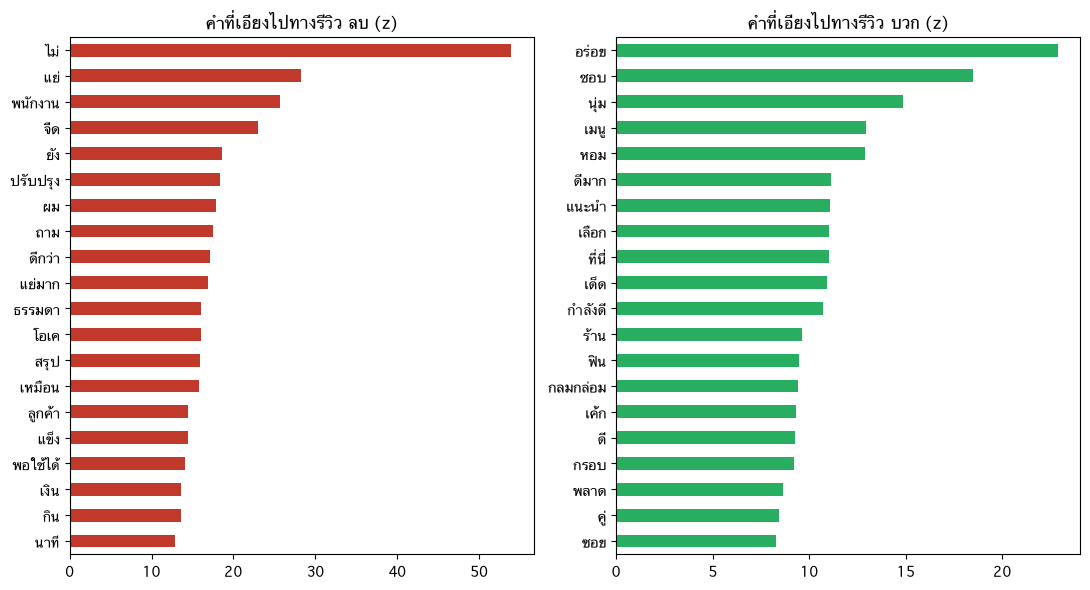

In [12]:
def log_odds(neg, pos, min_count=10, prior=1000):
    # Monroe et al. (2008). z > 0 means the word leans negative.
    df = pd.DataFrame({"neg": neg, "pos": pos}).fillna(0)
    df = df[df.neg + df.pos >= min_count]
    alpha = prior * (df.neg + df.pos) / (df.neg + df.pos).sum()  # prior ∝ overall frequency
    a0, n_neg, n_pos = alpha.sum(), df.neg.sum(), df.pos.sum()
    delta = (np.log((df.neg + alpha) / (n_neg + a0 - df.neg - alpha))
             - np.log((df.pos + alpha) / (n_pos + a0 - df.pos - alpha)))
    df["z"] = delta / np.sqrt(1 / (df.neg + alpha) + 1 / (df.pos + alpha))
    return df.sort_values("z")

lo = log_odds(neg, pos)

fig, ax = plt.subplots(1, 2, figsize=(11, 6))
lo.z.tail(20).plot.barh(ax=ax[0], color="#c0392b", title="คำที่เอียงไปทางรีวิว ลบ (z)")
lo.z.head(20).abs()[::-1].plot.barh(ax=ax[1], color="#27ae60", title="คำที่เอียงไปทางรีวิว บวก (z)")
plt.tight_layout()
plt.savefig(FIGS / "wongnai_log_odds.png", dpi=120)

In [13]:
lo[lo.index.isin(KEEP_WORDS)].sort_values("z", ascending=False).round(1)

,neg,pos,z
ไม่,8946.0,51888.0,53.9
ยัง,1024.0,5750.0,18.5
ห่วย,42.0,12.0,11.0
เลย,4203.0,39730.0,6.7
ที่สุด,150.0,1750.0,-1.2
มาก,2745.0,32589.0,-6.2
ดี,1705.0,22593.0,-9.3


**สิ่งที่เจอ (อ่านจากกราฟ)**
- ฝั่งลบมีคำที่บอก **สาเหตุ** ปนอยู่เยอะ: บริการ (พนักงาน, ลูกค้า, ถาม), การรอ (นาที), ราคา (เงิน), รสชาติ/เนื้อสัมผัส (จืด, แข็ง)
  และคำตัดสินแบบ "กลางๆ" (โอเค, ธรรมดา, พอใช้ได้, ดีกว่า, ปรับปรุง): รีวิวลบใน Wongnai มักสุภาพ ไม่ได้ด่าตรงๆ
- ฝั่งบวกเป็นคำชมรสชาติ/เนื้อสัมผัส (อร่อย, นุ่ม, หอม, กรอบ, กลมกล่อม) และคำแนะนำ (แนะนำ, ชอบ, ฟิน, พลาด จาก "ห้ามพลาด")
- "ผม" อยู่ฝั่งลบ: เป็นสัญญาณจาก **ผู้เขียน** ไม่ใช่เนื้อหา โมเดลอาจเรียนรู้ทางลัดแบบนี้ได้ ต้องจับตาใน error analysis
- รีวิวลบ **บอกว่าไม่ดีเรื่องอะไร** มากกว่ารีวิวบวก นี่คือเหตุผลที่ aspect มีค่าทางธุรกิจ
- **"ไม่" คือคำที่บ่งบอกรีวิวลบแรงที่สุดในทั้ง dataset** (z ≈ 54, ทิ้งอันดับสอง "แย่" ที่ ≈ 28 ห่างเกือบเท่าตัว; ดูตารางถัดไป)
  แต่ใน stopword list ของ PyThaiNLP มี "ไม่" อยู่
  ถ้าตัดทิ้ง "ไม่อร่อย" จะกลายเป็น "อร่อย" `ThaiTextCleaner` จึงเก็บคำกลุ่มนี้ไว้ (`KEEP_WORDS`)

**→ การตัดสินใจ**
- เก็บ negation ไว้ และใช้ bigram ใน TF-IDF (`ngram_range=(1,2)`) ให้โมเดลเห็น "ไม่ อร่อย" เป็นคู่
- เอาคำจากกราฟนี้ไปเป็น **seed keyword** ของ aspect ใน Phase 3 (ดู section 6)

## 6. แอบดู aspect ล่วงหน้า (เตรียม Phase 3)

ทดลอง keyword ง่ายๆ สำหรับ 4 aspect เป้าหมาย เพื่อตอบว่า **แต่ละ aspect ถูกพูดถึงบ่อยแค่ไหน** และ **โผล่ในรีวิวลบมากกว่าบวกไหม**

ข้อควรระวัง: นี่คือการนับ keyword ไม่ใช่ aspect จริง "ราคา" อาจโผล่ในประโยค "ราคาไม่แพง" (ชม) หรือ "แพงมาก" (ติ)
ตัวเลขนี้จึงเป็นแค่ **coverage** ใช้ประเมินว่าข้อมูลพอสำหรับ label เองหรือไม่ ไม่ใช่ผลลัพธ์

In [14]:
SEED = {
    "รสชาติ": ["อร่อย", "รสชาติ", "จืด", "เค็ม", "หวาน", "เผ็ด", "มัน", "สด", "คาว"],
    "ราคา": ["ราคา", "แพง", "ถูก", "คุ้ม", "บาท"],
    "บริการ": ["บริการ", "พนักงาน", "เสิร์ฟ", "รอ", "ช้า", "สุภาพ"],
    "บรรยากาศ": ["บรรยากาศ", "ร้าน", "ตกแต่ง", "สะอาด", "แอร์", "ที่นั่ง", "วิว"],
}

for aspect, keywords in SEED.items():
    lab[aspect] = lab.tokens.map(lambda toks: not set(keywords).isdisjoint(toks))

lab.groupby("y")[list(SEED)].mean().T.rename(columns={0: "negative", 1: "positive"}).round(2)

y,negative,positive
รสชาติ,0.86,0.87
ราคา,0.57,0.52
บริการ,0.49,0.37
บรรยากาศ,0.81,0.86


**→ การตัดสินใจ**
- "ร้าน" กับ "อร่อย" ถี่เกินจนแทบทุกรีวิวติด aspect: keyword กว้างไป จะต้องคัดใหม่ตอน label เอง
- **บริการ** ถูกพูดถึงในรีวิวลบสัดส่วนสูงกว่ารีวิวบวกชัดเจน สอดคล้องกับ log-odds ใน section 5
- keyword ทำงานระดับ **รีวิว** แต่รีวิว Wongnai ยาวและมีหลาย aspect ปนกัน ใน Phase 3 จึงควร **แยกเป็นประโยค**
  ก่อน label (300–500 ประโยค ไม่ใช่ 300–500 รีวิว) ไม่งั้นหนึ่ง label จะมีทั้งชมและติ
- aspect ในโค้ดเดิม (`src/aspects.py`: food / rider / delay / price) เป็นของ food delivery ต้องเปลี่ยนเป็นชุดใหม่นี้

## 7. Q6 — Wisesight ต่างจาก Wongnai อย่างไร

median words  Wongnai: 90.0  Wisesight: 10.0


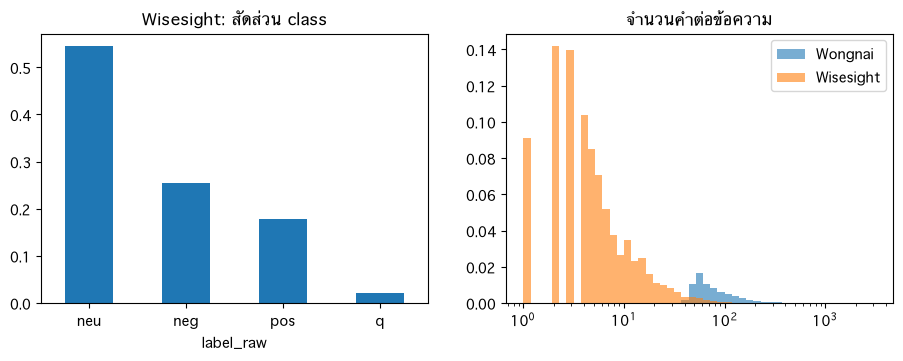

In [15]:
ws["tokens"] = ws.text.map(tokenize)
ws["n_words"] = ws.tokens.map(len)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ws.label_raw.value_counts(normalize=True).plot.bar(ax=ax[0], rot=0, title="Wisesight: สัดส่วน class")
bins = np.logspace(0, 3.5, 50)
ax[1].hist(wn.n_words, bins=bins, alpha=0.6, density=True, label="Wongnai")
ax[1].hist(ws.n_words, bins=bins, alpha=0.6, density=True, label="Wisesight")
ax[1].set_xscale("log"); ax[1].set_title("จำนวนคำต่อข้อความ"); ax[1].legend()
plt.savefig(FIGS / "wisesight_vs_wongnai.png", dpi=120, bbox_inches="tight")

print("median words  Wongnai:", wn.n_words.median(), " Wisesight:", ws.n_words.median())

In [16]:
for label in ["pos", "neg", "neu", "q"]:
    print(f"-- {label}")
    for t in ws.text[ws.label_raw == label].sample(3, random_state=3):
        print("  •", t[:120].replace("\n", " "))

-- pos
  • มิดจูววววว💕
  • รวมญาติ เพื่อbig cleaning บ้านสะอาดรับปีใหม่ สรงน้ำพระ เพื่อสิริมงคล #สวยกล้าท้าทุกแสง #คู่หูท้าแดด #kmacosmetics
  • รบกวนขอเบอร์ติดต่อกลับค่ะ เครือโตโยต้าดีเยี่ยมเหมือนกันค่ะ
-- neg
  • หายคนมารับแล้วไปส่งที่คอนโดหนึ่งอัตรตรา เมาคืนเมาไอเหี้ย เมาขนาดนี้ล่าสุดก็สี่ปีที่แล้ว พ่อมึงเป็นเจ้าของโรงงานabsoluteห
  • สั่งพาเลทนี้ทางเซโฟร่ากันเถอะค่ะ ไม่มีอะไรจะเสียแล้ว limited edition ด้วย และการที่มีสีคอนทัวร์คือ Hoola อันเดียวก็…
  • เควสชั่นของวันนี้คือ เมื่อไหร่เบียร์หมีจะกลับมา กูไปมาทุก 7-11 ไม่มีสักที่ อิเวน
-- neu
  • mk ชีสละ
  • ง่ะะ
  • กินติมม่ะ 555
-- q
  • Laneige ยังอยู่มั้ยคะ
  • มีใครไปเกาหลีหรือเห็นร้านรับพรีไหมคะ อยากได้ลิป Avene แพ็คคู่ตามรูปเลยค่ะ หาทุกทางแล้วไม่เจอที่ไหนขายเลย
  • ระหว่างตัวนี้กับสิวันนาตัวไหนน่าจะแมทกว่ากันค่ะ


In [17]:
# share of Wisesight tokens never seen in Wongnai train (out-of-vocabulary)
wn_vocab = {w for toks in wn.tokens[wn.split == "train"] for w in toks}
oov = np.mean([w not in wn_vocab for toks in ws.tokens for w in toks])
print(f"OOV: {oov:.1%}")

ws_bin = wisesight_to_binary(ws.label_raw).dropna()
print(f"pos/neg only: {len(ws_bin):,} rows ({len(ws_bin) / len(ws):.0%}), negative={1 - ws_bin.mean():.1%}")

OOV: 7.2%
pos/neg only: 11,589 rows (43%), negative=58.8%


**สิ่งที่เจอ**
- Wisesight คือ **social media หลายหมวด** (ความงาม, เครื่องดื่ม, ร้านอาหาร, การเมือง...) ไม่ใช่รีวิวร้านอาหาร
- ข้อความ **สั้นกว่ามาก** (หลักสิบคำ vs หลักร้อย) มีภาษาพูด, 555, อีโมจิ, ภาษาอังกฤษปน
- **neu เป็นส่วนใหญ่** และหลังตัด neu/q ออก class ลบกลับมีมากกว่าบวก **คนละทิศกับ Wongnai**
- label มี noise พอสมควร (เป็นเรื่องปกติของ dataset ที่คน label จาก social media)

**→ การตัดสินใจ**
- **Wongnai = ข้อมูลหลัก** สำหรับ train/test เพราะตรงกับโจทย์ "รีวิวร้านอาหาร"
- **Wisesight (pos/neg) = test set ข้ามโดเมน** วัดว่าโมเดลรับมือข้อความสั้นแบบ LINE ได้แค่ไหน
  OOV ระดับ token ต่ำ (~7%) ปัญหาจริงจึงไม่ใช่ "ไม่รู้จักคำ" แต่เป็น **ความยาว สไตล์ภาษา และหัวข้อ** ที่ต่างกัน
  สมมติฐาน: TF-IDF ที่ชินกับรีวิวยาวจะพลาดเยอะกับข้อความสั้น ส่วน WangchanBERTa ซึ่ง pretrain จากข้อความไทยหลายแหล่ง (รวม social media) น่าจะทนกว่า
  นี่จะเป็นแถวที่น่าสนใจที่สุดในตารางเทียบผลของ README
- Phase 2 จะลอง **เทรนรวม** Wongnai + Wisesight ด้วย แล้วดูว่าผลบน Wongnai test ลดลงไหม (trade-off ระหว่าง in-domain กับ robustness)
- `neu` ใช้ทีหลังได้ถ้าจะทำ 3 class แต่ตอนนี้ยังไม่ทำ (ทีละขั้น)

## 8. สรุปการตัดสินใจ

| เรื่อง | ตัดสินใจ | เหตุผล |
|---|---|---|
| ข้อมูลหลัก | Wongnai train/test ตามที่ publish | ตรงโจทย์, test set มีมาตรฐาน |
| นิยาม label | ≥4 บวก, ≤2 ลบ, ตัด 3 | 3 ดาวเป็นรีวิวผสม ทำให้ label noisy |
| ทำความสะอาด | ลบซ้ำใน train + ลบแถว train ที่ซ้ำกับ test | กัน leakage |
| Metric | macro-F1, F1 class ลบ, confusion matrix | class ลบมีแค่ ~8%; accuracy หลอกตา |
| Validation | stratified split จาก train (test ไม่แตะจนจบ) | กัน overfit กับ test |
| ข้อความยาว | max_length 416, ลอง head+tail truncation | รีวิวลบยาวและสรุปท้ายรีวิว |
| Wisesight | test ข้ามโดเมน (pos/neg) | วัดความทนต่อข้อความสั้นแบบ LINE |
| รีวิว 3 ดาว | เก็บไว้ทำ error analysis + aspect | เป็นแหล่งรีวิวผสมชั้นดี |

**ถัดไป:** `02_baseline.ipynb` เทรน TF-IDF + Logistic Regression ใหม่ตามการตัดสินใจข้างบน
และรายงานผลบน Wongnai test + Wisesight เป็นแถวแรกของตารางเทียบผล